# Lab 8 — Edge Detection

**Objective:** Apply Sobel, Prewitt and Canny edge detectors using Python/OpenCV and compare how Canny thresholds affect image details.

**New image:** Coffee-cup photo (different from `kid1.jpg` in the original notebook). The source photo is the `coffee` sample from scikit-image (CC0, Rachel Michetti).

**Before running:** Keep `coffee_photo.jpg` in the **same folder** as this notebook. Run cells from top to bottom.


## Setup — Import libraries and load the new image

We use the same grayscale image and the same **5 × 5 Gaussian blur** for all three detectors, so threshold comparisons differ only in their Canny parameters.

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Selected image: coffee photo (600 × 400 pixels)


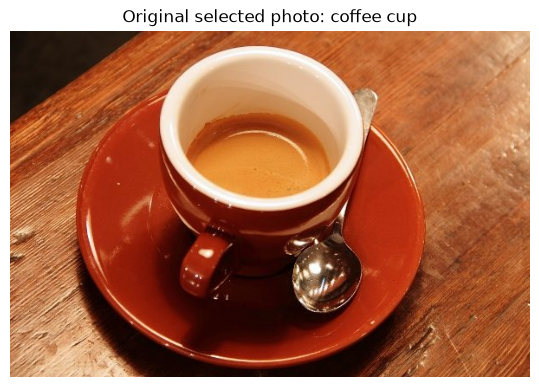

In [2]:
# Load the new photo from a normal image file.
img = cv2.imread("coffee_photo.jpg")
if img is None:
    raise FileNotFoundError("Place coffee_photo.jpg in the same folder as this notebook.")

img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
blurred = cv2.GaussianBlur(gray, (5, 5), 0)

print(f"Selected image: coffee photo ({img.shape[1]} × {img.shape[0]} pixels)")
plt.figure(figsize=(7, 4.5))
plt.imshow(img_rgb)
plt.title("Original selected photo: coffee cup")
plt.axis("off")
plt.show()

## Task 1 — Apply and compare edge detection methods

- **Sobel:** estimate the horizontal and vertical intensity gradients with `cv2.Sobel`.
- **Prewitt:** convolve with the two manually defined 3 × 3 Prewitt kernels using `cv2.filter2D`.
- **Canny:** detect thin binary edges using `cv2.Canny` with thresholds **50 and 150**.

Sobel and Prewitt are *gradient-magnitude* maps, whereas Canny produces a *binary* edge map. The two magnitude maps are independently normalized to 0–255 **for display only**.

In [3]:
# 1) Sobel detector: gradients in the x and y directions.
sobel_x = cv2.Sobel(blurred, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(blurred, cv2.CV_64F, 0, 1, ksize=3)
sobel_magnitude = cv2.magnitude(sobel_x, sobel_y)
sobel_edges = cv2.normalize(sobel_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 2) Prewitt detector: manual 3x3 kernels.
prewitt_kernel_x = np.array([[-1, 0, 1],
                             [-1, 0, 1],
                             [-1, 0, 1]], dtype=np.float64)
prewitt_kernel_y = np.array([[-1, -1, -1],
                             [ 0,  0,  0],
                             [ 1,  1,  1]], dtype=np.float64)
prewitt_x = cv2.filter2D(blurred, cv2.CV_64F, prewitt_kernel_x)
prewitt_y = cv2.filter2D(blurred, cv2.CV_64F, prewitt_kernel_y)
prewitt_magnitude = cv2.magnitude(prewitt_x, prewitt_y)
prewitt_edges = cv2.normalize(prewitt_magnitude, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 3) Canny detector (baseline: low=50, high=150).
canny_edges = cv2.Canny(blurred, 50, 150)

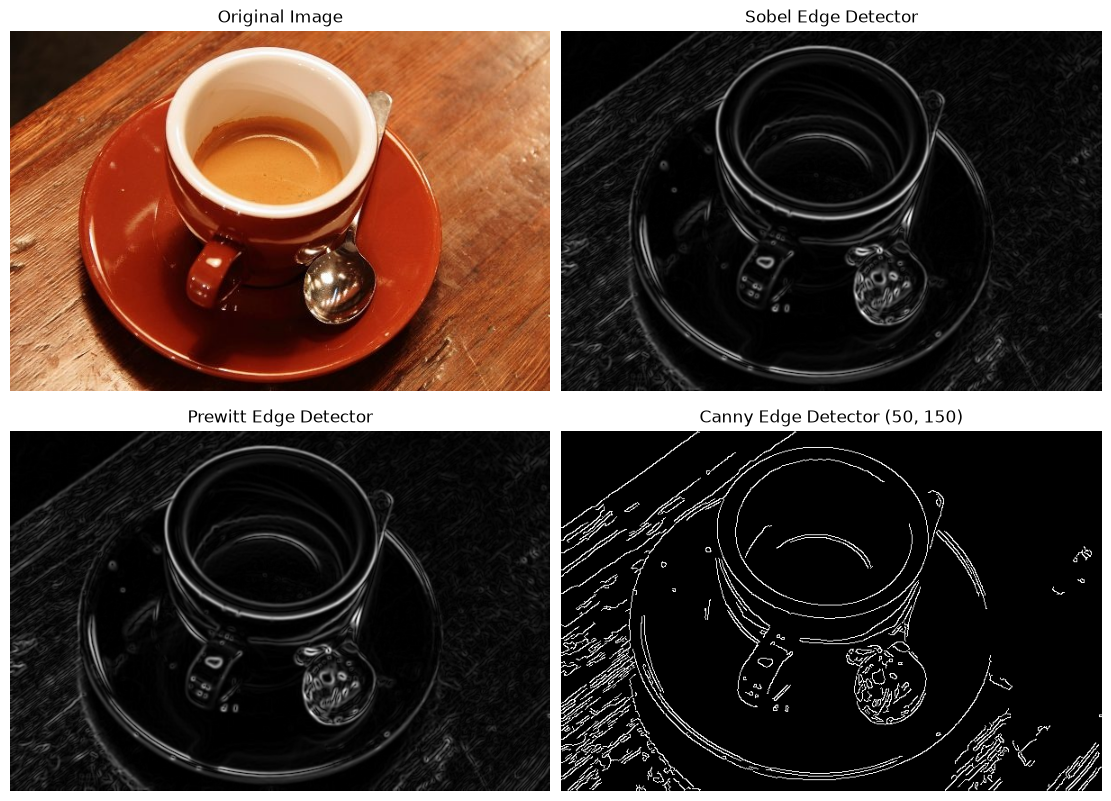

In [4]:
# Show the original image and all three resulting edge maps (Task 1).
fig, axes = plt.subplots(2, 2, figsize=(11, 8), layout="constrained")
plots = [
    (img_rgb, "Original Image", None),
    (sobel_edges, "Sobel Edge Detector", "gray"),
    (prewitt_edges, "Prewitt Edge Detector", "gray"),
    (canny_edges, "Canny Edge Detector (50, 150)", "gray"),
]
for ax, (photo, title, color_map) in zip(axes.flat, plots):
    ax.imshow(photo, cmap=color_map, vmin=0 if color_map else None, vmax=255 if color_map else None)
    ax.set_title(title)
    ax.axis("off")
plt.show()

### Task 1 — Observations

**Sobel and Prewitt** highlight changes in intensity as different brightness levels; they show continuous outlines and wood-grain texture but may display broad or soft edge responses. **Canny** creates thin, high-contrast binary contours, emphasizing the rims of the cup and saucer and parts of the spoon. Different output types mean their brightness values should not be compared as if they were the same measurement.

## Task 2 — Investigate the effect of Canny thresholds

Apply Canny to the **same blurred image** with exactly these threshold pairs: `(30, 90)`, `(50, 150)`, and `(100, 200)`.

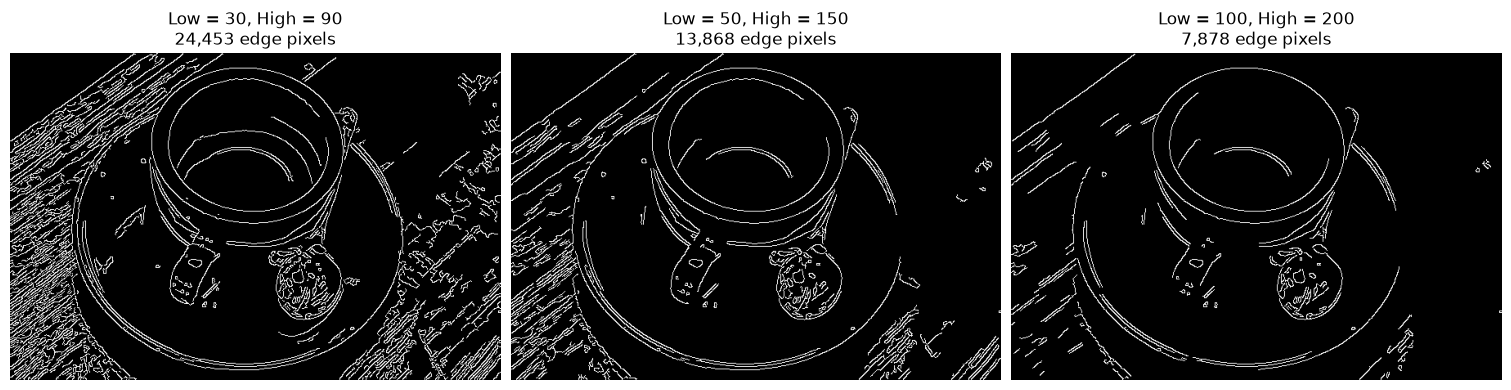

In [5]:
# Compare the three required Canny threshold pairs.
threshold_pairs = [(30, 90), (50, 150), (100, 200)]
canny_results = {}

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
for ax, (low, high) in zip(axes, threshold_pairs):
    edges = cv2.Canny(blurred, low, high)
    canny_results[(low, high)] = edges
    edge_count = np.count_nonzero(edges)
    ax.imshow(edges, cmap="gray", vmin=0, vmax=255)
    ax.set_title(f"Low = {low}, High = {high}\n{edge_count:,} edge pixels")
    ax.axis("off")
plt.show()

In [6]:
# Quantify edge counts (white pixels) and the percentage of the image they occupy.
print(f"{'Low / High':<16}{'Edge pixels':>14}{'Image area':>14}")
print("-" * 44)
for low, high in threshold_pairs:
    edge_count = int(np.count_nonzero(canny_results[(low, high)]))
    pct = 100 * edge_count / canny_results[(low, high)].size
    print(f"{str(low) + ' / ' + str(high):<16}{edge_count:>14,}{pct:>13.2f}%")

Low / High         Edge pixels    Image area
--------------------------------------------
30 / 90                 24,453        10.19%
50 / 150                13,868         5.78%
100 / 200                7,878         3.28%


### Task 2 — Explanation

1. **Low = 30, High = 90:** The most permissive pair. More weak and connected edges survive; wood grain and small image details are more visible, but the map is also more cluttered.
2. **Low = 50, High = 150:** A middle setting. Many strong object boundaries remain, while some low-contrast texture disappears. It balances detail and visual clarity.
3. **Low = 100, High = 200:** The strictest pair. Fewer pixels are identified as edges; the dominant cup/saucer contours remain while weaker details are suppressed, so some subtle features are lost.

**Why:** Canny uses *hysteresis thresholding*. Strong responses above the upper threshold are accepted; responses below the lower threshold are rejected; intermediate responses survive only if connected to strong edges. Raising both thresholds usually reduces the number of retained edges (for this fixed image and preprocessing). Edge pixels are measured with `np.count_nonzero`, not manually estimated.

### Conclusion

Thresholds control the trade-off between **detecting fine detail** and **suppressing weak/noisy edges**. Sobel and Prewitt visualize gradient strength; Canny gives thinner binary edges and allows this trade-off to be adjusted with two thresholds.

## References

1. OpenCV, [Sobel Derivatives](https://docs.opencv.org/4.12.0/d2/d2c/tutorial_sobel_derivatives.html).
2. OpenCV, [Canny Edge Detector](https://docs.opencv.org/4.12.0/da/d5c/tutorial_canny_detector.html).
3. scikit-image, [sample `coffee` photo](https://scikit-image.org/docs/stable/api/skimage.data.html#skimage.data.coffee) — CC0 by Rachel Michetti.
4. The uploaded **Lab 8 - Edge Detection** reference notebook (Sobel, Prewitt and Canny examples).